In [ ]:
!pip install pandas

### Librerias usadas
* Pandas
* matplotlib
* numpy


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

### Datasets
* Publicaciones
* Usuarios
* Categorias
* Reseñas

In [ ]:
publicaciones = pd.read_csv("../data/raw/listings.csv")
print(publicaciones.shape)
publicaciones.head()

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
print(usuarios.shape)
usuarios.head()

In [ ]:
categoria = pd.read_csv("../data/raw/categories.csv")
print(categoria.shape)
categoria.head()

In [ ]:
resenas = pd.read_csv("../data/raw/reviews.csv")
print(categoria.shape)
resenas.head()


In [ ]:


publicaciones = pd.read_csv("../data/raw/listings.csv")
usuarios = pd.read_csv("../data/raw/profiles.csv")
categoria = pd.read_csv("../data/raw/categories.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuarios.shape



### Left right
* left_on // [variableName] = [tableNombre].merge([tableMerge], left_on="[tableNombre]", right_on ="[tableMerge])

In [ ]:
resenas = pd.read_csv("../data/raw/reviews.csv")
resenas['created_at'] = pd.to_datetime(resenas['created_at'])
resenas = resenas.groupby(resenas['created_at'].dt.day_of_week)['id'].count()
resenas = resenas.reindex(range(7),fill_value=0)
fig, ax =plt.subplots(figsize=(10,5))
ax.plot(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], resenas.values, 
        marker='o', color='darkblue', 
        markerfacecolor='red', markeredgecolor='red')

ax.grid(alpha=.3)
ax.set_xlabel('Dias', weight='bold')
ax.set_ylabel('reseñas por dia', weight='bold' )
ax.set_title('Dias de la semana con mas reseñas', weight='bold')



In [ ]:
publi_usuario = publicaciones.merge(usuarios, left_on="user_id", right_on="id")
publi_usuario.head()


## Quien publico mas
publi_usuario.groupby(nombreCliente)["IDENTIFICADOR"]  
[] => Va el identificador  
([asd]) ->asd=agrupar 
groupby() agrupar segun   
.count() cuenta los valores de las columnas  
.size() cuanta todas las filas de cada grupo  


In [ ]:
pVentas = publi_usuario.groupby("username")["user_id"].count()
pVentas =pVentas.sort_values(ascending=False).head(5)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["black"])
plt.figure(figsize=(8,4))
plt.barh(pVentas.index, pVentas.values)
plt.gca().invert_yaxis()
plt.xlabel("Numero de publicaciones")
plt.title("Usuarios con mas publicaciones")
plt.show()


In [ ]:
pVentas = publi_usuario.groupby("username").size()
print(pVentas.idxmax()," ",pVentas.max())

## Que publicacion cuesta mas de [x] 
* publiRango = publicaciones[publicaciones["price"]>500]  
* {variable} = DATAFRAME[CONDICION]  
### Salida   
#### publiRango =publiRango.sort_values(by="price", ascending=False)  
* {variable} = {variable}.sort_values(by="{columna}", ascending={Bool})  
#### publiRango[["title","price"]].head(5)
* {variable}[["{columnas},{columnas}]].head({n}) **n** entero cantidad de registros 

In [ ]:
publicaciones.head()

In [ ]:
publiRango = publicaciones[publicaciones["price"]>500]
publiRango =publiRango.sort_values(by="price", ascending=False)
publiRango[["title","price"]].head(5)

## **Categoria que tiene mas publicaciones**

In [ ]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias.head()

In [ ]:
# hacer un merge
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name")["category_id"].count()
publiCategorias.sort_values(ascending=False)

## Grafico tarta categorias

In [ ]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name")["category_id"].count()
publiCategorias = publiCategorias.sort_values(ascending=False).head(10)
colores = plt.cm.tab10(np.linspace(0, 1, len(publiCategorias)))
fig, ax = plt.subplots()
pie = ax.pie(publiCategorias.values, 
       colors=colores, radius=0.9,)

ax.pie_label(pie,'{frac:.1%}\n{absval:d}',
       textprops=dict(color="w",size=12, weight="bold"))
ax.legend(pie.wedges, publiCategorias.index ,title="Categorias",loc="center left", 
          bbox_to_anchor=(1, 0, 0.5, 1) )
ax.set_title("Categorias con mas publicaciones", weight="bold")
ax.axis("equal")
plt.show()

In [ ]:
publiCategorias = publicaciones.merge(categoria, left_on="category_id", right_on="id")
publiCategorias= publiCategorias.groupby("name").size()
publiCategorias.sort_values(ascending=False)

## Cual es el precio promedio de cada categoria

In [ ]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio.sort_values(ascending=False)

In [ ]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio = catePromedio.sort_values(ascending=False)
catePromedio

In [ ]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio = catePromedio.sort_values(ascending=False)
catePromedio

In [ ]:
catePromedio = publicaciones.merge(categoria, left_on="category_id", right_on="id")
catePromedio = catePromedio.groupby("name")["price"].mean()
catePromedio = catePromedio.sort_values(ascending=False)
fig, ax=plt.subplots(figsize=(10,9))
barras = ax.barh(catePromedio.index, catePromedio.values, color ="Blue")
ax.invert_yaxis()
ax.set_xlabel("Precio promedio", weight="bold")
ax.set_title("Precio promedio de cada categoria", weight="bold")
ax.tick_params(axis='y', labelsize=9)
ax.bar_label(barras, fmt="S/ %.2f", padding=5)
ax.set_xlim(0, catePromedio.max()*1.20)
plt.tight_layout()
plt.show()

___
### Usuario que recibio mas reseñas

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas.sort_values(ascending=False)



Text(0, 0.5, 'N Publicaciones')

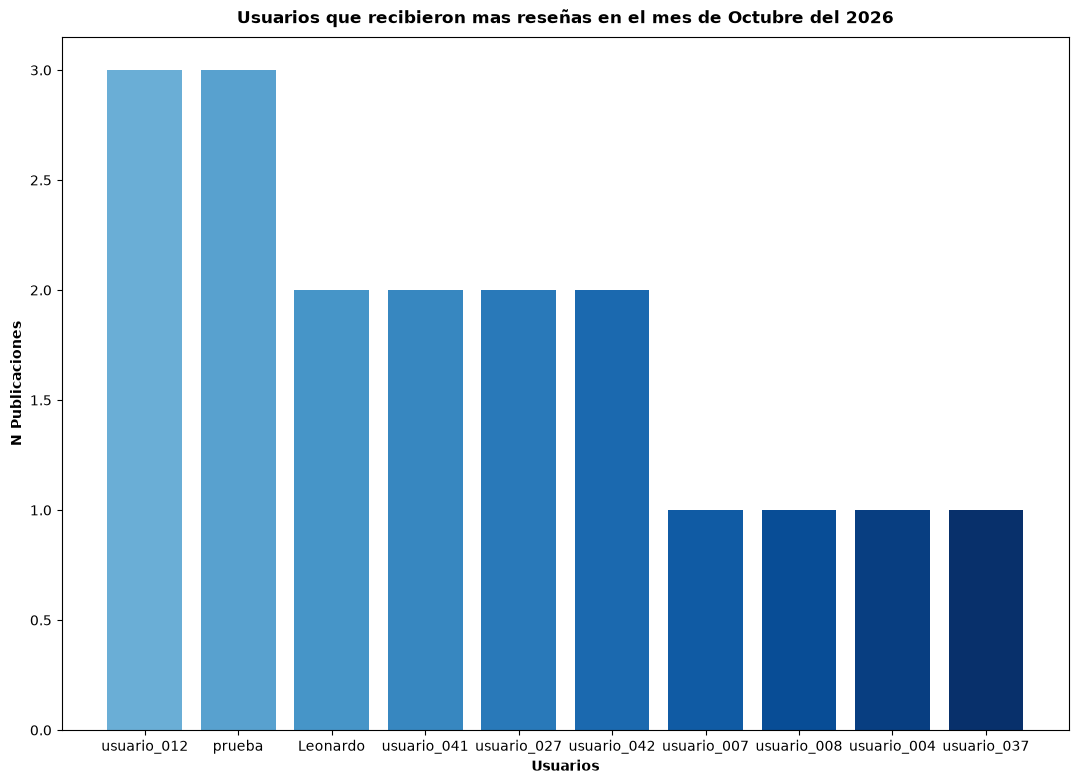

In [124]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
colores = plt.cm.Blues(np.linspace(0.5, 1, len(usuResenas)))
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas['created_at_x'] = pd.to_datetime(usuResenas['created_at_x'])
usuResenas = usuResenas[(usuResenas['created_at_x'].dt.month == 10) & 
                        (usuResenas['created_at_x'].dt.year ==2026)]
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas= usuResenas.sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(13,9))

barras = ax.bar(usuResenas.index, usuResenas.values, color=colores)
ax.set_title('Usuarios que recibieron mas reseñas en el mes de Octubre del 2026', weight='bold', pad=10)
ax.set_xlabel('Usuarios', weight='bold')
ax.set_ylabel('N Publicaciones', weight='bold')

#usuResenas[usuResenas['created_at'].dt.month==10]
#usuResenas = usuResenas.sort_values(ascending=False).head(5)
#colores = plt.cm.Blues(np.linspace(1, 0.2, len(usuResenas)))
#fig, ax = plt.subplots(figsize=(10,7))
#bar = ax.bar(usuResenas.index, usuResenas.values, color= colores)
#ax.set_title("Usuarios que recibieron mas reseñas en el ultimo mes")

___
### Usuario que recibio mas reseñas positivas


In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas[usuResenas["rating"]>=4]
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas.sort_values(ascending=False)

___
### Usuario que recibio mas reseñas negativas

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")
colores = plt.cm.Blues(np.linspace(1, 0.5, len(usuResenas)))
usuResenas = resenas.merge(usuarios, left_on="reviewed_user_id", right_on="id")
usuResenas = usuResenas[usuResenas["rating"]<4]
promedio = usuResenas[usuResenas["rating"]<4]['rating'].mean()
usuResenas = usuResenas.groupby("username")["reviewed_user_id"].count()
usuResenas = usuResenas.sort_values(ascending=False).head()
fig, ax = plt.subplots(figsize=(10,9))


barras = ax.bar(usuResenas.index, usuResenas.values, color=colores)
ax.set_title('Usuarios que recibieron reseñas menores a 4 estrellas', weight='bold', pad=10)
ax.set_xlabel('Usuarios', weight='bold')
ax.set_ylabel('N Publicaciones', weight='bold')

___
### Quien escribio mas reseñas


In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")

usuResenas = resenas.merge(usuarios, left_on="reviewer_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewer_id"].count()
usuResenas= usuResenas.sort_values(ascending=False).head(10)
usuResenas

In [ ]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")

usuResenas = resenas.merge(usuarios, left_on="reviewer_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewer_id"].count()
usuResenas= usuResenas.sort_values(ascending=False).head(10)
usuResenas

Text(0, 0.5, 'N publicaciones')

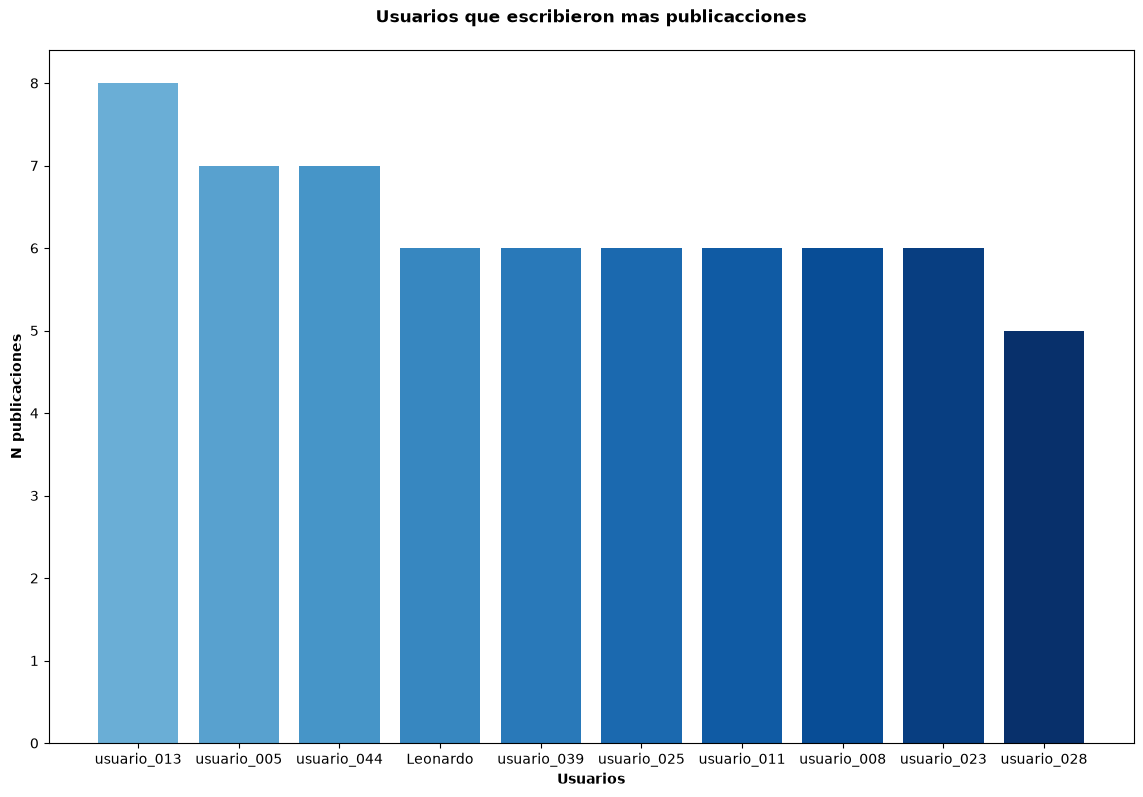

In [121]:
usuarios = pd.read_csv("../data/raw/profiles.csv")
resenas = pd.read_csv("../data/raw/reviews.csv")

usuResenas = resenas.merge(usuarios, left_on="reviewer_id", right_on="id")
usuResenas = usuResenas.groupby("username")["reviewer_id"].count()
usuResenas= usuResenas.sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(14,9))
colores = plt.cm.Blues(np.linspace(0.5,1, len(usuResenas)))

barras = ax.bar(usuResenas.index, usuResenas.values, color=colores)
ax.set_title('Usuarios que escribieron mas publicacciones', weight='bold', pad=20)
ax.set_xlabel('Usuarios', weight='bold')
ax.set_ylabel('N publicaciones', weight='bold')

### Que dia de la semana hay mas publicaciones

Text(0.5, 1.0, 'Dias de la semana con mas reseñas')

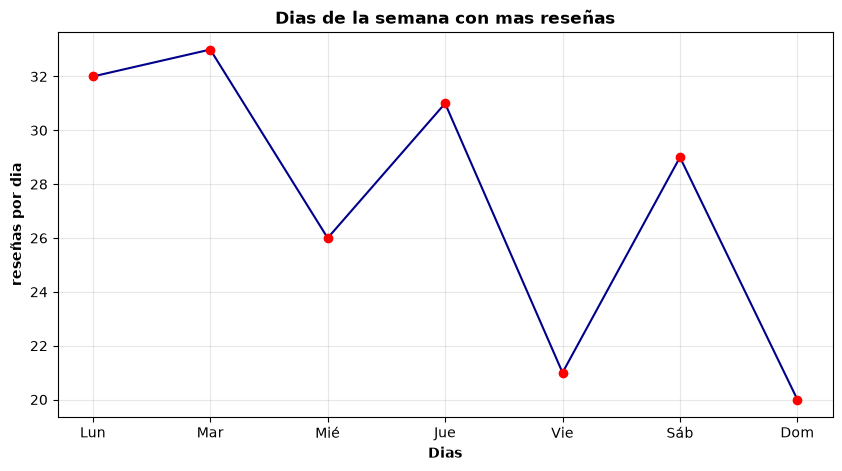

In [122]:
resenas = pd.read_csv("../data/raw/reviews.csv")
resenas['created_at'] = pd.to_datetime(resenas['created_at'])
resenas = resenas.groupby(resenas['created_at'].dt.day_of_week)['id'].count()
resenas = resenas.reindex(range(7),fill_value=0)
fig, ax =plt.subplots(figsize=(10,5))
ax.plot(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], resenas.values, 
        marker='o', color='darkblue', 
        markerfacecolor='red', markeredgecolor='red')

ax.grid(alpha=.3)
ax.set_xlabel('Dias', weight='bold')
ax.set_ylabel('reseñas por dia', weight='bold' )
ax.set_title('Dias de la semana con mas reseñas', weight='bold')



In [ ]:
publi = pd.read_csv("../data/raw/listings.csv")
publi['created_at'] = pd.to_datetime(publi['created_at'])
publi = publi.groupby(publi['created_at'].dt.day_of_week)['id'].count()
publi = publi.reindex(range(7),fill_value=0)
publi

Text(0.5, 1.0, 'Dias de la semana con mas publicaciones')

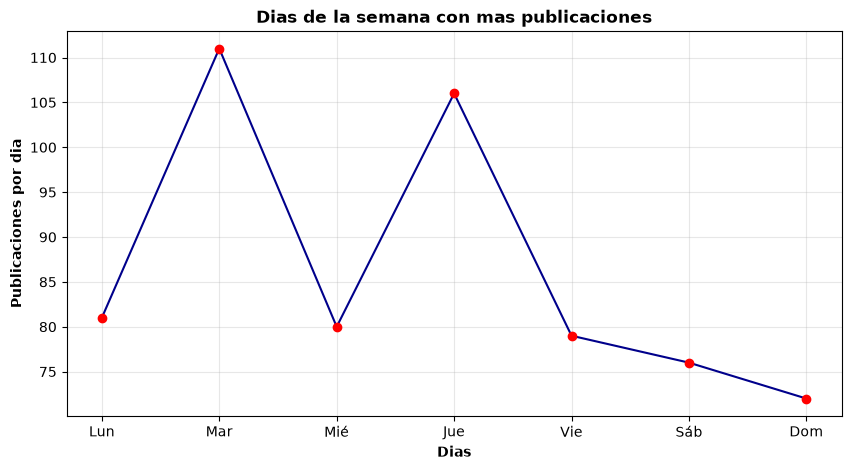

In [123]:
publi = pd.read_csv("../data/raw/listings.csv")
publi['created_at'] = pd.to_datetime(publi['created_at'])
publi = publi.groupby(publi['created_at'].dt.day_of_week)['id'].count()
publi = publi.reindex(range(7),fill_value=0)
fig, ax =plt.subplots(figsize=(10,5))
ax.plot(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], publi.values, 
        marker='o', color='darkblue', 
        markerfacecolor='red', markeredgecolor='red')

ax.grid(alpha=.3)
ax.set_xlabel('Dias', weight='bold')
ax.set_ylabel('Publicaciones por dia', weight='bold' )
ax.set_title('Dias de la semana con mas publicaciones', weight='bold')

